# E1 — Softmax, MLP và CNN trên Fashion-MNIST

**Câu hỏi nghiên cứu:** tăng độ phức tạp từ mô hình tuyến tính đến CNN cải thiện accuracy và thay đổi loại lỗi như thế nào?

Notebook dùng cùng split 54k/6k/10k với E2–E3, tự viết training loop PyTorch và chỉ đưa kết quả `full` vào báo cáo.


## 1. Môi trường


### 1.1. Cài đặt thư viện

**Mục tiêu:** Kiểm tra các dependency nền tảng và chỉ cài những gói còn thiếu trong runtime.

**Kết quả:** Môi trường có đủ PyTorch, torchvision, NumPy, pandas, scikit-learn và các thư viện vẽ biểu đồ.

**Lưu ý:** Kaggle hoặc Colab có thể yêu cầu khởi động lại kernel nếu pip thay đổi package đã được nạp.


In [1]:
import importlib.util, subprocess, sys

required = {
    "torch": "torch>=2.2,<3",
    "torchvision": "torchvision>=0.17,<1",
    "numpy": "numpy>=1.26,<3",
    "pandas": "pandas>=2.1,<4",
    "matplotlib": "matplotlib>=3.8,<4",
    "seaborn": "seaborn>=0.13,<1",
    "sklearn": "scikit-learn>=1.4,<2",
    "tqdm": "tqdm>=4.66,<5",
}
missing = [package for module, package in required.items() if importlib.util.find_spec(module) is None]
if missing:
    subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", *missing])
print("Dependencies ready")


Dependencies ready


### 1.2. Import và chọn thiết bị

**Mục tiêu:** Nạp thư viện dùng chung, chọn CPU/GPU và xác định có bật mixed precision hay không.

**Kết quả:** Tạo `DEVICE`, `AMP_ENABLED` và các namespace được dùng trong toàn notebook.


In [2]:
import copy
import csv
import hashlib
import json
import math
import os
import platform
import random
import time
from contextlib import nullcontext
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
import sklearn
import torch
import torch.nn as nn
import torch.nn.functional as F
import torchvision
from sklearn.metrics import confusion_matrix, f1_score
from sklearn.model_selection import StratifiedShuffleSplit
from torch.utils.data import DataLoader, Dataset, Subset
from torchvision import datasets, transforms
from tqdm.auto import tqdm

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
AMP_ENABLED = DEVICE.type == "cuda"
print("device:", DEVICE)


device: cuda


## 2. Cấu hình


### 2.1. Khai báo cấu hình chạy

**Mục tiêu:** Thiết lập đường dẫn dữ liệu/artifact, seed, batch size, số epoch, chế độ `smoke` hoặc `full` và danh sách experiment.

**Kết quả:** Tạo dictionary `CONFIG`; ở chế độ `smoke`, notebook tự giảm ngân sách để kiểm tra pipeline.


In [3]:
def default_root(kind):
    env_name = "CO5085_DATA_ROOT" if kind == "data" else "CO5085_OUTPUT_ROOT"
    if os.getenv(env_name):
        return Path(os.environ[env_name])
    if Path("/kaggle/working").exists():
        return Path("/kaggle/working") / ("data" if kind == "data" else "artifacts")
    if Path("/content").exists():
        return Path("/content") / ("data" if kind == "data" else "artifacts")
    return Path("./data" if kind == "data" else "./artifacts")


CONFIG = {
    "data_root": str(default_root("data")),
    "output_root": str(default_root("output")),
    "run_mode": os.getenv("CO5085_RUN_MODE", "full"),
    "experiment_ids": [],  # Empty means all experiments for this notebook.
    "seed": 42,
    "batch_size": 128,
    "epochs": 20,
    "resume_from": None,  # None, "last", or a checkpoint path.
    "evaluate_only": os.getenv("CO5085_EVALUATE_ONLY", "0") == "1",
    "num_workers": 2,
}
assert CONFIG["run_mode"] in {"smoke", "full"}
if CONFIG["run_mode"] == "smoke":
    CONFIG["epochs"] = 1
    CONFIG["num_workers"] = 0
print(json.dumps(CONFIG, indent=2))


{
  "data_root": "/content/data",
  "output_root": "/content/artifacts",
  "run_mode": "full",
  "experiment_ids": [],
  "seed": 42,
  "batch_size": 128,
  "epochs": 20,
  "resume_from": null,
  "evaluate_only": false,
  "num_workers": 2
}


### 2.2. Khởi tạo tiện ích thực nghiệm

**Mục tiêu:** Định nghĩa các hàm seed, hash split, checkpoint nguyên tử, resume, training loop, metric và biểu đồ dùng chung.

**Kết quả:** Cung cấp toàn bộ hàm hạ tầng cho các cell dữ liệu, huấn luyện và đánh giá phía sau.

**Lưu ý:** Cell này chỉ định nghĩa hàm, chưa bắt đầu huấn luyện.


In [4]:
def seed_everything(seed):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False


def environment_info():
    return {
        "python": platform.python_version(),
        "platform": platform.platform(),
        "torch": torch.__version__,
        "torchvision": torchvision.__version__,
        "sklearn": sklearn.__version__,
        "cuda": torch.version.cuda,
        "device": torch.cuda.get_device_name(0) if torch.cuda.is_available() else "cpu",
    }


def json_dump(value, path):
    path = Path(path)
    path.parent.mkdir(parents=True, exist_ok=True)
    with path.open("w", encoding="utf-8") as handle:
        json.dump(value, handle, indent=2, ensure_ascii=False, default=str)


def atomic_torch_save(value, path):
    path = Path(path)
    path.parent.mkdir(parents=True, exist_ok=True)
    temporary = path.with_suffix(path.suffix + ".tmp")
    torch.save(value, temporary)
    temporary.replace(path)


def rng_state():
    return {
        "python": random.getstate(),
        "numpy": np.random.get_state(),
        "torch": torch.get_rng_state(),
        "cuda": torch.cuda.get_rng_state_all() if torch.cuda.is_available() else None,
    }


def restore_rng_state(state):
    random.setstate(state["python"])
    np.random.set_state(state["numpy"])
    torch.set_rng_state(state["torch"])
    if torch.cuda.is_available() and state.get("cuda") is not None:
        torch.cuda.set_rng_state_all(state["cuda"])


def count_parameters(model):
    total = sum(p.numel() for p in model.parameters())
    trainable = sum(p.numel() for p in model.parameters() if p.requires_grad)
    size_mb = sum(p.numel() * p.element_size() for p in model.parameters()) / 2**20
    return {"parameters": total, "trainable_parameters": trainable, "weight_size_mb": size_mb}


def split_digest(train_idx, val_idx):
    digest = hashlib.sha256()
    digest.update(np.asarray(train_idx, dtype=np.int64).tobytes())
    digest.update(np.asarray(val_idx, dtype=np.int64).tobytes())
    return digest.hexdigest()


def fashion_split(dataset, data_root, seed=42):
    split_path = Path(data_root) / "fashion_mnist_split_seed42.npz"
    labels = np.asarray(dataset.targets)
    splitter = StratifiedShuffleSplit(n_splits=1, test_size=6000, random_state=seed)
    expected_train, expected_val = next(splitter.split(np.zeros(len(labels)), labels))
    if split_path.exists():
        saved = np.load(split_path)
        train_idx, val_idx = saved["train_idx"], saved["val_idx"]
        if not (np.array_equal(train_idx, expected_train) and np.array_equal(val_idx, expected_val)):
            raise RuntimeError(f"Split file does not match seed={seed}: {split_path}")
    else:
        split_path.parent.mkdir(parents=True, exist_ok=True)
        np.savez(split_path, train_idx=expected_train, val_idx=expected_val)
        train_idx, val_idx = expected_train, expected_val
    assert len(train_idx) == 54000 and len(val_idx) == 6000
    assert not set(train_idx).intersection(set(val_idx))
    return train_idx, val_idx, split_digest(train_idx, val_idx)


def classification_epoch(model, loader, criterion, optimizer=None, scaler=None,
                         max_batches=None, grad_clip=None, grad_accum=1, frozen_eval=None):
    training = optimizer is not None
    model.train(training)
    if training and frozen_eval is not None:
        frozen_eval(model)
    if training:
        optimizer.zero_grad(set_to_none=True)
    total_loss = total_correct = total_items = 0
    accumulation_count = 0
    start = time.perf_counter()
    context = torch.enable_grad if training else torch.no_grad
    with context():
        for batch_index, (images, labels) in enumerate(loader):
            if max_batches is not None and batch_index >= max_batches:
                break
            images, labels = images.to(DEVICE), labels.to(DEVICE)
            with torch.amp.autocast("cuda", enabled=AMP_ENABLED):
                logits = model(images)
                loss = criterion(logits, labels)
                backward_loss = loss / grad_accum
            if training:
                scaler.scale(backward_loss).backward()
                accumulation_count += 1
                should_step = accumulation_count == grad_accum
                if should_step:
                    if grad_clip is not None:
                        scaler.unscale_(optimizer)
                        nn.utils.clip_grad_norm_(model.parameters(), grad_clip)
                    scaler.step(optimizer)
                    scaler.update()
                    optimizer.zero_grad(set_to_none=True)
                    accumulation_count = 0
            total_loss += loss.item() * labels.size(0)
            total_correct += (logits.argmax(1) == labels).sum().item()
            total_items += labels.size(0)
        if training and accumulation_count:
            if grad_clip is not None:
                scaler.unscale_(optimizer)
                nn.utils.clip_grad_norm_(model.parameters(), grad_clip)
            scaler.step(optimizer)
            scaler.update()
            optimizer.zero_grad(set_to_none=True)
    elapsed = time.perf_counter() - start
    return {"loss": total_loss / total_items, "accuracy": total_correct / total_items,
            "items": total_items, "seconds": elapsed}


@torch.no_grad()
def predict_classifier(model, loader, max_batches=None):
    model.eval()
    labels_all, predictions_all, probabilities_all = [], [], []
    for batch_index, (images, labels) in enumerate(loader):
        if max_batches is not None and batch_index >= max_batches:
            break
        logits = model(images.to(DEVICE))
        probabilities = logits.softmax(1).cpu()
        labels_all.append(labels.cpu())
        predictions_all.append(probabilities.argmax(1))
        probabilities_all.append(probabilities)
    return (torch.cat(labels_all).numpy(), torch.cat(predictions_all).numpy(),
            torch.cat(probabilities_all).numpy())


def resolve_resume(run_dir, resume_from):
    if resume_from is None:
        return None
    if resume_from == "last":
        candidate = Path(run_dir) / "last.pt"
    else:
        candidate = Path(resume_from)
    return candidate if candidate.exists() else None


def fit_classifier(model, loaders, optimizer, scheduler, run_dir, run_config,
                   grad_clip=None, grad_accum=1, frozen_eval=None):
    run_dir = Path(run_dir)
    run_dir.mkdir(parents=True, exist_ok=True)
    json_dump(run_config, run_dir / "config.json")
    json_dump(environment_info(), run_dir / "environment.json")
    criterion = nn.CrossEntropyLoss()
    scaler = torch.amp.GradScaler("cuda", enabled=AMP_ENABLED)
    start_epoch, best_accuracy, best_loss, history = 0, -1.0, float("inf"), []
    if run_config.get("evaluate_only"):
        evaluation_path = run_dir / "best.pt"
        if not evaluation_path.exists():
            raise FileNotFoundError(f"evaluate_only requires {evaluation_path}")
        checkpoint = torch.load(evaluation_path, map_location=DEVICE, weights_only=False)
        model.load_state_dict(checkpoint["model"])
        start_epoch = run_config["epochs"]
        best_accuracy, best_loss = checkpoint["best_accuracy"], checkpoint["best_loss"]
        history_path = run_dir / "history.csv"
        if history_path.exists():
            history = pd.read_csv(history_path).to_dict("records")
    else:
        resume_path = resolve_resume(run_dir, run_config.get("resume_from"))
        checkpoint = torch.load(resume_path, map_location=DEVICE, weights_only=False) if resume_path is not None else None
    if not run_config.get("evaluate_only") and checkpoint is not None:
        model.load_state_dict(checkpoint["model"])
        optimizer.load_state_dict(checkpoint["optimizer"])
        if scheduler is not None and checkpoint.get("scheduler") is not None:
            scheduler.load_state_dict(checkpoint["scheduler"])
        if checkpoint.get("scaler") is not None:
            scaler.load_state_dict(checkpoint["scaler"])
        restore_rng_state(checkpoint["rng_state"])
        start_epoch = checkpoint["epoch"] + 1
        best_accuracy, best_loss = checkpoint["best_accuracy"], checkpoint["best_loss"]
        history_path = run_dir / "history.csv"
        if history_path.exists():
            history = pd.read_csv(history_path).to_dict("records")

    if torch.cuda.is_available():
        torch.cuda.reset_peak_memory_stats()
    for epoch in range(start_epoch, run_config["epochs"]):
        train_stats = classification_epoch(
            model, loaders["train"], criterion, optimizer, scaler,
            max_batches=run_config.get("max_train_batches"), grad_clip=grad_clip,
            grad_accum=grad_accum, frozen_eval=frozen_eval,
        )
        val_stats = classification_epoch(
            model, loaders["val"], criterion,
            max_batches=run_config.get("max_eval_batches"),
        )
        if scheduler is not None:
            scheduler.step()
        row = {
            "epoch": epoch,
            "train_loss": train_stats["loss"], "train_accuracy": train_stats["accuracy"],
            "val_loss": val_stats["loss"], "val_accuracy": val_stats["accuracy"],
            "epoch_seconds": train_stats["seconds"],
            "learning_rate": optimizer.param_groups[0]["lr"],
        }
        history.append(row)
        pd.DataFrame(history).to_csv(run_dir / "history.csv", index=False)
        improved = (val_stats["accuracy"] > best_accuracy or
                    (val_stats["accuracy"] == best_accuracy and val_stats["loss"] < best_loss))
        if improved:
            best_accuracy, best_loss = val_stats["accuracy"], val_stats["loss"]
        state = {
            "model": model.state_dict(), "optimizer": optimizer.state_dict(),
            "scheduler": scheduler.state_dict() if scheduler is not None else None,
            "scaler": scaler.state_dict(), "epoch": epoch,
            "best_accuracy": best_accuracy, "best_loss": best_loss,
            "rng_state": rng_state(), "config": run_config,
        }
        atomic_torch_save(state, run_dir / "last.pt")
        if improved:
            atomic_torch_save(state, run_dir / "best.pt")
        print(f"epoch={epoch + 1}/{run_config['epochs']} train={train_stats['accuracy']:.4f} val={val_stats['accuracy']:.4f}")

    best = torch.load(run_dir / "best.pt", map_location=DEVICE, weights_only=False)
    model.load_state_dict(best["model"])
    val_stats = classification_epoch(model, loaders["val"], criterion,
                                     max_batches=run_config.get("max_eval_batches"))
    test_stats = classification_epoch(model, loaders["test"], criterion,
                                      max_batches=run_config.get("max_eval_batches"))
    metrics = {
        "run_mode": run_config["run_mode"], "best_epoch": best["epoch"],
        "val_loss": val_stats["loss"], "val_accuracy": val_stats["accuracy"],
        "test_loss": test_stats["loss"], "test_accuracy": test_stats["accuracy"],
        "peak_gpu_memory_mb": (torch.cuda.max_memory_allocated() / 2**20
                               if torch.cuda.is_available() else 0.0),
        **count_parameters(model),
    }
    y_true, y_pred, probabilities = predict_classifier(
        model, loaders["test"], max_batches=run_config.get("max_eval_batches"))
    np.savez_compressed(run_dir / "predictions.npz", y_true=y_true, y_pred=y_pred,
                        probabilities=probabilities)
    json_dump(metrics, run_dir / "metrics.json")
    return metrics, pd.DataFrame(history), (y_true, y_pred, probabilities)


@torch.no_grad()
def benchmark_model(model, sample, repeats=30, warmup=5):
    model.eval()
    sample = sample.to(DEVICE)
    for _ in range(warmup):
        model(sample)
    if torch.cuda.is_available():
        torch.cuda.synchronize()
        torch.cuda.reset_peak_memory_stats()
    start = time.perf_counter()
    for _ in range(repeats):
        model(sample)
    if torch.cuda.is_available():
        torch.cuda.synchronize()
    elapsed = time.perf_counter() - start
    return {
        "latency_ms_per_image": 1000 * elapsed / (repeats * len(sample)),
        "benchmark_batch_size": len(sample),
        "benchmark_peak_memory_mb": (torch.cuda.max_memory_allocated() / 2**20
                                     if torch.cuda.is_available() else 0.0),
    }


def plot_history(history, path):
    frame = pd.DataFrame(history)
    figure, axes = plt.subplots(1, 2, figsize=(11, 4))
    axes[0].plot(frame.epoch, frame.train_loss, label="train")
    axes[0].plot(frame.epoch, frame.val_loss, label="validation")
    axes[0].set(title="Loss", xlabel="Epoch")
    axes[1].plot(frame.epoch, frame.train_accuracy, label="train")
    axes[1].plot(frame.epoch, frame.val_accuracy, label="validation")
    axes[1].set(title="Accuracy", xlabel="Epoch")
    for axis in axes:
        axis.legend(); axis.grid(alpha=.2)
    figure.tight_layout(); figure.savefig(path, dpi=160); plt.close(figure)


def plot_confusion(y_true, y_pred, class_names, path, normalize=True):
    matrix = confusion_matrix(y_true, y_pred, normalize="true" if normalize else None)
    size = max(7, min(20, len(class_names) * .22))
    figure, axis = plt.subplots(figsize=(size, size))
    sns.heatmap(matrix, cmap="Blues", xticklabels=class_names, yticklabels=class_names,
                annot=len(class_names) <= 10, fmt=".2f" if normalize else "d", ax=axis)
    axis.set(xlabel="Predicted", ylabel="True", title="Confusion matrix")
    figure.tight_layout(); figure.savefig(path, dpi=160); plt.close(figure)


def completed_metrics(run_dir, run_mode, expected_parameters=None):
    path = Path(run_dir) / "metrics.json"
    if not path.exists():
        return None
    with path.open(encoding="utf-8") as handle:
        metrics = json.load(handle)
    if expected_parameters is not None and metrics.get("parameters") != expected_parameters:
        if CONFIG["evaluate_only"] or CONFIG["resume_from"] is not None:
            raise ValueError(
                "CNN architecture changed: start a fresh run with resume_from=None and "
                "evaluate_only=False, or select the output_root of a matching run."
            )
        print("Ignoring metrics from a different CNN architecture:", path)
        return None
    return metrics if metrics.get("run_mode") == run_mode else None


seed_everything(CONFIG["seed"])
Path(CONFIG["data_root"]).mkdir(parents=True, exist_ok=True)
Path(CONFIG["output_root"]).mkdir(parents=True, exist_ok=True)


## 3. Dữ liệu, split và EDA


### 3.1. Chuẩn bị Fashion-MNIST

**Mục tiêu:** Tải dữ liệu, tạo split phân tầng 54.000/6.000/10.000, tính thống kê chuẩn hóa từ train và dựng DataLoader.

**Kết quả:** Tạo `train_dataset`, `val_dataset`, `test_dataset`, `loaders`, `CLASS_NAMES` và `SPLIT_HASH`.

**Lưu ý:** Nếu file split đã tồn tại nhưng khác seed 42, notebook dừng để bảo vệ tính tái lập.


In [5]:
raw_train = datasets.FashionMNIST(CONFIG["data_root"], train=True, download=True)
mean = (raw_train.data.float() / 255.0).mean().item()
std = (raw_train.data.float() / 255.0).std().item()
transform = transforms.Compose([transforms.ToTensor(), transforms.Normalize((mean,), (std,))])
train_full = datasets.FashionMNIST(CONFIG["data_root"], train=True, transform=transform, download=True)
test_dataset = datasets.FashionMNIST(CONFIG["data_root"], train=False, transform=transform, download=True)
train_idx, val_idx, SPLIT_HASH = fashion_split(raw_train, CONFIG["data_root"], CONFIG["seed"])
train_dataset, val_dataset = Subset(train_full, train_idx), Subset(train_full, val_idx)

loaders = {
    "train": DataLoader(train_dataset, batch_size=CONFIG["batch_size"], shuffle=True,
                        num_workers=CONFIG["num_workers"], pin_memory=AMP_ENABLED),
    "val": DataLoader(val_dataset, batch_size=CONFIG["batch_size"], shuffle=False,
                      num_workers=CONFIG["num_workers"], pin_memory=AMP_ENABLED),
    "test": DataLoader(test_dataset, batch_size=CONFIG["batch_size"], shuffle=False,
                       num_workers=CONFIG["num_workers"], pin_memory=AMP_ENABLED),
}
CLASS_NAMES = list(raw_train.classes)
print({"mean": mean, "std": std, "split_hash": SPLIT_HASH,
       "sizes": [len(train_dataset), len(val_dataset), len(test_dataset)]})


100%|██████████| 26.4M/26.4M [00:01<00:00, 19.3MB/s]
100%|██████████| 29.5k/29.5k [00:00<00:00, 306kB/s]
100%|██████████| 4.42M/4.42M [00:00<00:00, 5.67MB/s]
100%|██████████| 5.15k/5.15k [00:00<00:00, 11.8MB/s]


{'mean': 0.2860405743122101, 'std': 0.3530242443084717, 'split_hash': 'bbadd2fc92455ce7f7ca22890516a1f02c47a663679ec246709d7cf0cfdcb075', 'sizes': [54000, 6000, 10000]}


### 3.2. Quan sát mẫu dữ liệu

**Mục tiêu:** Hiển thị mười ảnh train sau khi hoàn nguyên chuẩn hóa để kiểm tra nhãn và chất lượng đầu vào.

**Kết quả:** Sinh một lưới ảnh Fashion-MNIST phục vụ EDA; cell không thay đổi dataset.


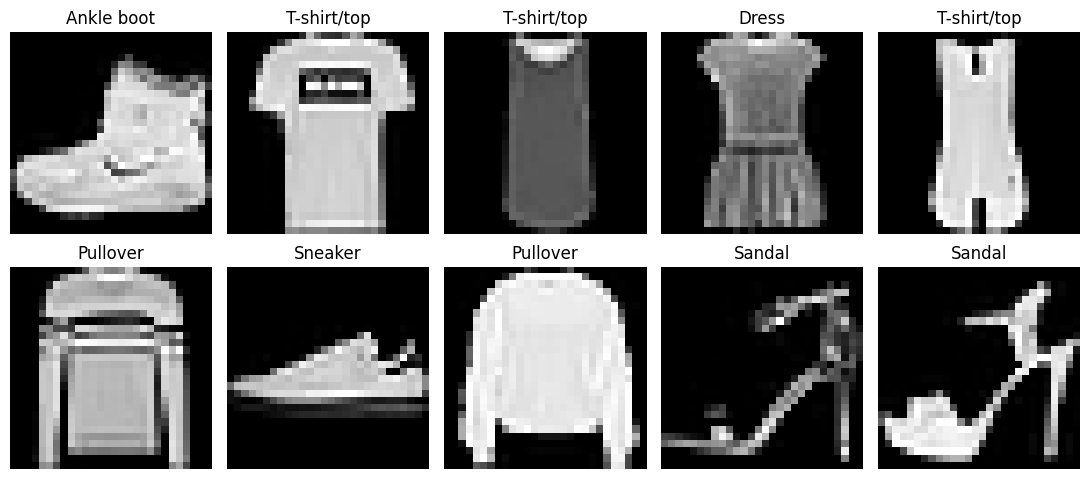

In [6]:
figure, axes = plt.subplots(2, 5, figsize=(11, 5))
for axis, (image, label) in zip(axes.ravel(), [train_full[i] for i in range(10)]):
    axis.imshow(image.squeeze() * std + mean, cmap="gray", vmin=0, vmax=1)
    axis.set_title(CLASS_NAMES[label]); axis.axis("off")
plt.tight_layout(); plt.show()


## 4. Mô hình


### 4.1. Định nghĩa ba baseline

**Mục tiêu:** Cài đặt Softmax tuyến tính, MLP hai tầng ẩn và CNN hai block tích chập + Flatten 3136 + Linear với cùng đầu ra 10 logits.

**Kết quả:** Tạo `MODEL_FACTORIES`, ba experiment ID và danh sách `selected` lấy từ cấu hình.

**Lưu ý:** CNN có 50.186 tham số so với 235.146 của MLP (ít hơn 78,7%). Head tuyến tính giữ thông tin vị trí trên feature map 7×7; accuracy cần đo bằng full run mới. Checkpoint CNN GAP cũ không tương thích.


In [7]:
class SoftmaxClassifier(nn.Module):
    def __init__(self):
        super().__init__()
        self.linear = nn.Linear(28 * 28, 10)

    def forward(self, images):
        return self.linear(images.flatten(1))


class MLPClassifier(nn.Module):
    def __init__(self):
        super().__init__()
        self.network = nn.Sequential(
            nn.Flatten(), nn.Linear(28 * 28, 256), nn.ReLU(),
            nn.Linear(256, 128), nn.ReLU(), nn.Linear(128, 10),
        )

    def forward(self, images):
        return self.network(images)


class CNNClassifier(nn.Module):
    def __init__(self):
        super().__init__()
        self.features = nn.Sequential(
            nn.Conv2d(1, 32, 3, padding=1), nn.ReLU(), nn.MaxPool2d(2),
            nn.Conv2d(32, 64, 3, padding=1), nn.ReLU(), nn.MaxPool2d(2),
        )
        self.head = nn.Linear(64 * 7 * 7, 10)

    def forward(self, images):
        return self.head(self.features(images).flatten(1))


MODEL_FACTORIES = {"softmax": SoftmaxClassifier, "mlp": MLPClassifier, "cnn": CNNClassifier}
assert sum(parameter.numel() for parameter in CNNClassifier().parameters()) == 50186
assert sum(parameter.numel() for parameter in CNNClassifier().parameters()) < sum(
    parameter.numel() for parameter in MLPClassifier().parameters())
EXPERIMENT_IDS = list(MODEL_FACTORIES)
selected = CONFIG["experiment_ids"] or EXPERIMENT_IDS
unknown = set(selected) - set(EXPERIMENT_IDS)
if unknown:
    raise ValueError(f"Unknown experiment IDs: {sorted(unknown)}")
print("Selected:", selected)


Selected: ['softmax', 'mlp', 'cnn']


## 5. Kiểm tra nhanh: overfit một batch và gradient hữu hạn


### 5.1. Chạy sanity check

**Mục tiêu:** Huấn luyện từng mô hình được chọn trên một mini-batch nhỏ để xác nhận loss giảm và mọi gradient đều hữu hạn.

**Kết quả:** In loss đầu/cuối; assertion sẽ dừng notebook nếu pipeline forward/backward có lỗi.


In [8]:
def overfit_one_batch(factory, steps=30):
    seed_everything(CONFIG["seed"])
    model = factory().to(DEVICE)
    images, labels = next(iter(loaders["train"]))
    images, labels = images[:32].to(DEVICE), labels[:32].to(DEVICE)
    optimizer = torch.optim.Adam(model.parameters(), lr=3e-3)
    initial = None
    for step in range(steps):
        optimizer.zero_grad(set_to_none=True)
        loss = F.cross_entropy(model(images), labels)
        if initial is None:
            initial = loss.item()
        loss.backward()
        assert all(torch.isfinite(p.grad).all() for p in model.parameters() if p.grad is not None)
        optimizer.step()
    assert loss.item() < initial, (initial, loss.item())
    return initial, loss.item()


for experiment_id in selected:
    print(experiment_id, "one-batch sanity:", overfit_one_batch(
        MODEL_FACTORIES[experiment_id], 10 if CONFIG["run_mode"] == "smoke" else 30))


softmax one-batch sanity: (2.5494651794433594, 0.012322857975959778)
mlp one-batch sanity: (2.3024544715881348, 4.4597160012926906e-05)
cnn one-batch sanity: (2.3216500282287598, 0.0004823245108127594)


## 6. Huấn luyện và chọn checkpoint


### 6.1. Chạy ma trận E1

**Mục tiêu:** Huấn luyện các experiment đã chọn, resume khi cần, đánh giá checkpoint tốt nhất và đo latency/bộ nhớ.

**Kết quả:** Ghi config, history, checkpoint, predictions, metrics, learning curves, confusion matrix và `summary.csv`.

**Lưu ý:** Run đã hoàn tất sẽ được bỏ qua; chỉ kết quả `full` nên dùng trong báo cáo chính.


In [9]:
summary = []
OUTPUT_BASE = Path(CONFIG["output_root"]) / "E1" / CONFIG["run_mode"]
for experiment_id in selected:
    run_dir = OUTPUT_BASE / experiment_id
    existing = completed_metrics(
        run_dir, CONFIG["run_mode"], expected_parameters=50186 if experiment_id == "cnn" else None)
    if existing is not None and not CONFIG["evaluate_only"]:
        print("skip completed:", experiment_id)
        summary.append({"experiment_id": experiment_id, **existing})
        continue
    seed_everything(CONFIG["seed"])
    model = MODEL_FACTORIES[experiment_id]().to(DEVICE)
    optimizer = torch.optim.Adam(model.parameters(), lr=1e-3)
    run_config = {
        **CONFIG, "assignment": "E1", "experiment_id": experiment_id,
        "split_hash": SPLIT_HASH, "normalization": {"mean": mean, "std": std},
        "max_train_batches": 4 if CONFIG["run_mode"] == "smoke" else None,
        "max_eval_batches": 2 if CONFIG["run_mode"] == "smoke" else None,
    }
    metrics, history, predictions = fit_classifier(
        model, loaders, optimizer, None, run_dir, run_config)
    sample_images, _ = next(iter(loaders["test"]))
    metrics.update(benchmark_model(model, sample_images[:32], repeats=5 if CONFIG["run_mode"] == "smoke" else 30))
    json_dump(metrics, run_dir / "metrics.json")
    plot_history(history, run_dir / "curves.png")
    plot_confusion(predictions[0], predictions[1], CLASS_NAMES, run_dir / "confusion_matrix.png")
    summary.append({"experiment_id": experiment_id, **metrics})

summary_frame = pd.DataFrame(summary).sort_values("experiment_id")
summary_frame.to_csv(OUTPUT_BASE / "summary.csv", index=False)
display(summary_frame)


epoch=1/20 train=0.7982 val=0.8428
epoch=2/20 train=0.8414 val=0.8550
epoch=3/20 train=0.8507 val=0.8605
epoch=4/20 train=0.8523 val=0.8610
epoch=5/20 train=0.8557 val=0.8600
epoch=6/20 train=0.8571 val=0.8612
epoch=7/20 train=0.8590 val=0.8598
epoch=8/20 train=0.8605 val=0.8620
epoch=9/20 train=0.8616 val=0.8630
epoch=10/20 train=0.8617 val=0.8623
epoch=11/20 train=0.8607 val=0.8632
epoch=12/20 train=0.8636 val=0.8633
epoch=13/20 train=0.8633 val=0.8637
epoch=14/20 train=0.8648 val=0.8635
epoch=15/20 train=0.8639 val=0.8633
epoch=16/20 train=0.8651 val=0.8650
epoch=17/20 train=0.8658 val=0.8608
epoch=18/20 train=0.8629 val=0.8635
epoch=19/20 train=0.8667 val=0.8588
epoch=20/20 train=0.8665 val=0.8623
epoch=1/20 train=0.8218 val=0.8678
epoch=2/20 train=0.8673 val=0.8725
epoch=3/20 train=0.8815 val=0.8825
epoch=4/20 train=0.8918 val=0.8815
epoch=5/20 train=0.8986 val=0.8862
epoch=6/20 train=0.9048 val=0.8903
epoch=7/20 train=0.9091 val=0.8950
epoch=8/20 train=0.9146 val=0.8993
epoch=9/2

,experiment_id,run_mode,best_epoch,val_loss,val_accuracy,test_loss,test_accuracy,peak_gpu_memory_mb,parameters,trainable_parameters,weight_size_mb,latency_ms_per_image,benchmark_batch_size,benchmark_peak_memory_mb
2,cnn,full,12,0.218884,0.929833,0.253161,0.9195,42.917480,50186,50186,0.191444,0.019553,32,42.221191
1,mlp,full,15,0.304049,0.905833,0.369971,0.8933,23.668457,235146,235146,0.897011,0.004503,32,20.100586
0,softmax,full,15,0.392103,0.865000,0.450101,0.8410,18.038574,7850,7850,0.029945,0.005475,32,17.439453


## 7. Đánh giá, phân tích lỗi và xuất artifact


### 7.1. Trực quan hóa dự đoán sai

**Mục tiêu:** Chọn các mẫu test bị phân loại sai có độ tin cậy cao nhất và hoàn nguyên ảnh để quan sát.

**Kết quả:** Lưu `failures.png` trong thư mục từng experiment và in đường dẫn artifact gốc.


In [10]:
def plot_failures(dataset, predictions_path, path, count=16):
    saved = np.load(predictions_path)
    y_true, y_pred, probabilities = saved["y_true"], saved["y_pred"], saved["probabilities"]
    wrong = np.flatnonzero(y_true != y_pred)
    confidence = probabilities[np.arange(len(y_pred)), y_pred]
    chosen = wrong[np.argsort(confidence[wrong])[-count:][::-1]]
    rows = max(1, math.ceil(len(chosen) / 4))
    figure, axes = plt.subplots(rows, 4, figsize=(10, 2.6 * rows))
    for axis, index in zip(np.asarray(axes).ravel(), chosen):
        image, _ = dataset[index]
        axis.imshow(image.squeeze().numpy() * std + mean, cmap="gray", vmin=0, vmax=1)
        axis.set_title(f"true={CLASS_NAMES[y_true[index]]}\npred={CLASS_NAMES[y_pred[index]]} ({confidence[index]:.2f})")
        axis.axis("off")
    for axis in np.asarray(axes).ravel()[len(chosen):]:
        axis.axis("off")
    figure.tight_layout(); figure.savefig(path, dpi=160); plt.close(figure)


for experiment_id in selected:
    run_dir = OUTPUT_BASE / experiment_id
    if (run_dir / "predictions.npz").exists():
        plot_failures(test_dataset, run_dir / "predictions.npz", run_dir / "failures.png")
print("Artifacts:", OUTPUT_BASE)


Artifacts: /content/artifacts/E1/full


## 8. Câu hỏi phân tích

1. Khoảng cách train/validation của ba mô hình cho biết gì về underfitting và overfitting?
2. Accuracy tăng thêm có tương xứng với số tham số, latency và dung lượng model không?
3. Những cặp lớp nào bị nhầm nhiều nhất? Quan sát nào trong ảnh giải thích được lỗi?
4. CNN sửa được loại lỗi nào của MLP, và vẫn thất bại ở loại lỗi nào?

Viết kết luận từ artifact của run `full`; không suy diễn từ smoke run.
